# Figs 1–2 explained by example

Written by a reviewer who did not write `src/figures.py`. Each section takes one behaviour worth checking, states in one
sentence what it should do, and runs the **real** function on a small input. The `expected` values are written first,
from `audit/contracts/F12_figures.md`, `audit/decisions.md` (C1, C2, pinned Figs defaults) and `audit/data_facts.md`,
never from the code. Each table shows **input | expected | code gives**. A mismatch is marked POSSIBLE BUG; all
mismatches are collected and the last cell fails if there are any.

Figures are display tier: no Codex brief, so the 4 checks were chosen from the contract.

In [1]:
import itertools
import os
import sys
from pathlib import Path
from unittest import mock

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from IPython.display import display

from src import figures as F

FAILURES = []


def compare(table, name, expected_col="expected", actual_col="code gives"):
    """Show the table; record (not stop on) any row where expected differs from what the code gives."""
    table["match"] = [e == a for e, a in zip(table[expected_col], table[actual_col])]
    display(table)
    if not table["match"].all():
        print(f"POSSIBLE BUG in {name}:")
        display(table[~table["match"]])
        FAILURES.append(name)


def bar_values(ax):
    """Bar heights read off a stacked-bar panel: one row per bar (left to right), one column per stacked cell type."""
    return pd.DataFrame({c.get_label(): [b.get_height() for b in c] for c in ax.containers})

## 1. Composition table and proportions (`composition_counts`, `plot_fig1`)

**Should do:** count cells per (donor, condition) × cell type, rows in `DONOR_ORDER` × [ctrl, stim], columns in
`STACK_ORDER`; the proportions panel shows each bar divided by its own total.

Toy: one cell of every cell type in every donor × condition (128 cells), plus 1 extra B cell in `patient_1039` ctrl
and 2 extra NK cells in `patient_101` stim. Rows are shuffled so the order must come from the code, not the input.

| group | expected count | expected proportion |
|---|---|---|
| patient_1039 ctrl, B cells | 2 | 2/9 |
| patient_1039 ctrl, any other type | 1 | 1/9 |
| patient_101 stim, NK cells | 3 | 3/10 |
| patient_101 stim, any other type | 1 | 1/10 |
| every other group, any type | 1 | 1/8 |

,input,expected,code gives,match
0,row order,"[(patient_1039, ctrl), (patient_1039, stim), (...","[(patient_1039, ctrl), (patient_1039, stim), (...",True
1,column order,"[B cells, CD14+ Monocytes, CD4 T cells, CD8 T ...","[B cells, CD14+ Monocytes, CD4 T cells, CD8 T ...",True
2,count values,"[[2, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, ...","[[2, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, ...",True
3,counts panel bar heights,"[[2, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, ...","[[2.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], [1....",True
4,proportions panel bar heights,"[[0.222222, 0.111111, 0.111111, 0.111111, 0.11...","[[0.222222, 0.111111, 0.111111, 0.111111, 0.11...",True


,group,B cells prop,NK cells prop
0,patient_1039 ctrl,0.222,0.111
1,patient_101 stim,0.100,0.300
2,patient_1015 stim,0.125,0.125


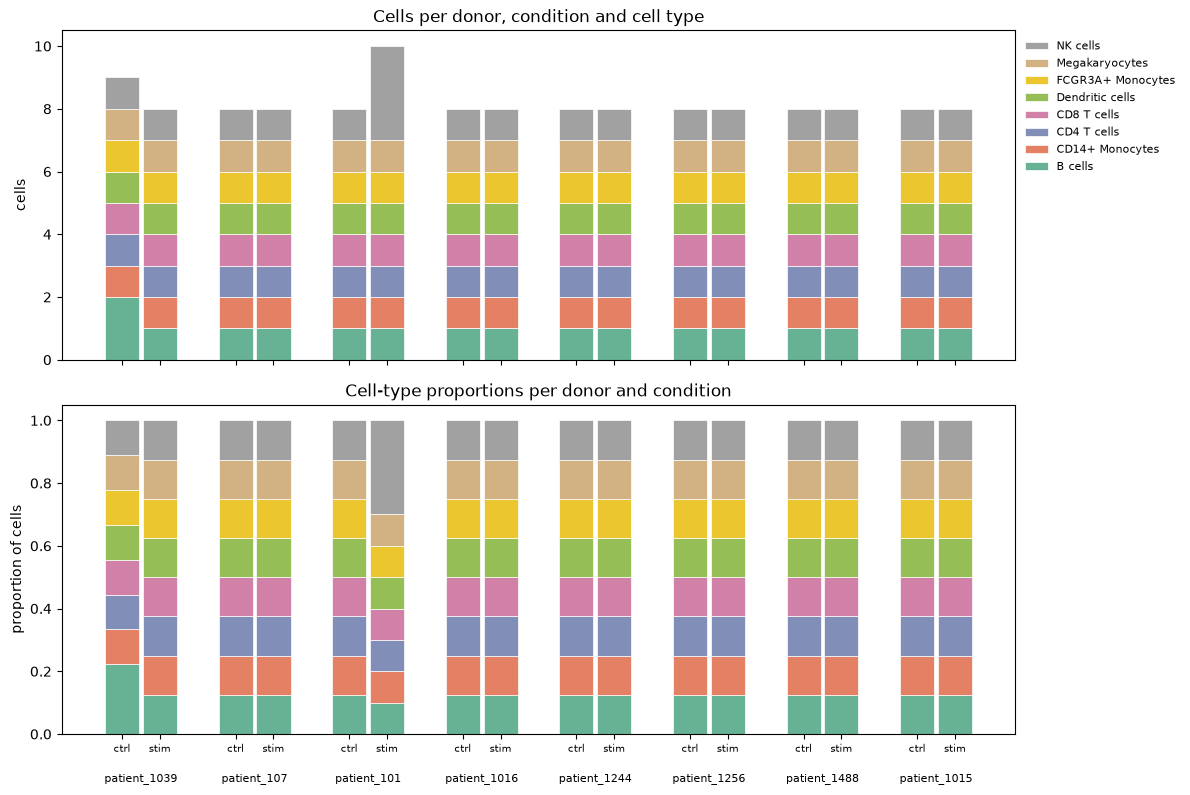

In [2]:
rows = list(itertools.product(F.DONOR_ORDER, ["ctrl", "stim"], F.STACK_ORDER))
rows += [("patient_1039", "ctrl", "B cells")] + [("patient_101", "stim", "NK cells")] * 2
toy_obs = pd.DataFrame(rows, columns=["donor", "condition", "cell_type"]).sample(frac=1, random_state=1)

# Expected, written from the contract: rows DONOR_ORDER x [ctrl, stim], columns STACK_ORDER.
exp_index = pd.MultiIndex.from_product([F.DONOR_ORDER, ["ctrl", "stim"]], names=["donor", "condition"])
exp_counts = pd.DataFrame(1, index=exp_index, columns=F.STACK_ORDER)
exp_counts.loc[("patient_1039", "ctrl"), "B cells"] = 2
exp_counts.loc[("patient_101", "stim"), "NK cells"] = 3
exp_props = exp_counts.div(exp_counts.sum(axis=1), axis=0)

counts = F.composition_counts(toy_obs)
fig = F.plot_fig1(counts)
ax_counts, ax_props = fig.axes[:2]

compare(pd.DataFrame({
    "input": ["row order", "column order", "count values", "counts panel bar heights", "proportions panel bar heights"],
    "expected": [list(exp_index), F.STACK_ORDER, exp_counts.to_numpy().tolist(),
                 exp_counts.to_numpy().tolist(), np.round(exp_props.to_numpy(), 6).tolist()],
    "code gives": [list(counts.index), list(counts.columns), counts.to_numpy().tolist(),
                   bar_values(ax_counts)[F.STACK_ORDER].to_numpy().tolist(),
                   np.round(bar_values(ax_props)[F.STACK_ORDER].to_numpy(), 6).tolist()],
}), "1 composition toy")
display(pd.DataFrame({"group": ["patient_1039 ctrl", "patient_101 stim", "patient_1015 stim"],
                      "B cells prop": exp_props["B cells"].loc[[("patient_1039", "ctrl"), ("patient_101", "stim"), ("patient_1015", "stim")]].round(3).to_numpy(),
                      "NK cells prop": exp_props["NK cells"].loc[[("patient_1039", "ctrl"), ("patient_101", "stim"), ("patient_1015", "stim")]].round(3).to_numpy()}))

A missing group must not be silently filled with zeros (CLAUDE.md rule 0: no workarounds; every donor must have both
conditions). Drop all `patient_107` stim cells: **expected** an error.

In [3]:
def run(obs):
    try:
        F.composition_counts(obs)
        return "no error"
    except (KeyError, ValueError) as e:
        return f"error ({type(e).__name__})"

missing = toy_obs[~((toy_obs.donor == "patient_107") & (toy_obs.condition == "stim"))]
compare(pd.DataFrame({"input": ["toy minus patient_107 stim"], "expected": ["error"],
                      "code gives": [run(missing).split(" ")[0]]}), "1 missing group")

,input,expected,code gives,match
0,toy minus patient_107 stim,error,error,True


## 2. Fig 1 on the real data: bar totals = `audit/data_facts.md`

**Should do:** each Fig 1 bar's height (sum of its stacked segments) equals cells per donor × condition in
`data_facts.md`, and all bars sum to 24,562 (contract step 1).

,input: bar,expected,code gives,match
0,patient_1039 ctrl,408,408,True
1,patient_1039 stim,584,584,True
2,patient_107 ctrl,517,517,True
3,patient_107 stim,525,525,True
4,patient_101 ctrl,858,858,True
5,patient_101 stim,1166,1166,True
6,patient_1016 ctrl,1723,1723,True
7,patient_1016 stim,1635,1635,True
8,patient_1244 ctrl,1879,1879,True
9,patient_1244 stim,1464,1464,True


,input,expected,code gives,match
0,sum of all bars,24562,24562,True
1,proportion bars each sum to 1,True,True,True


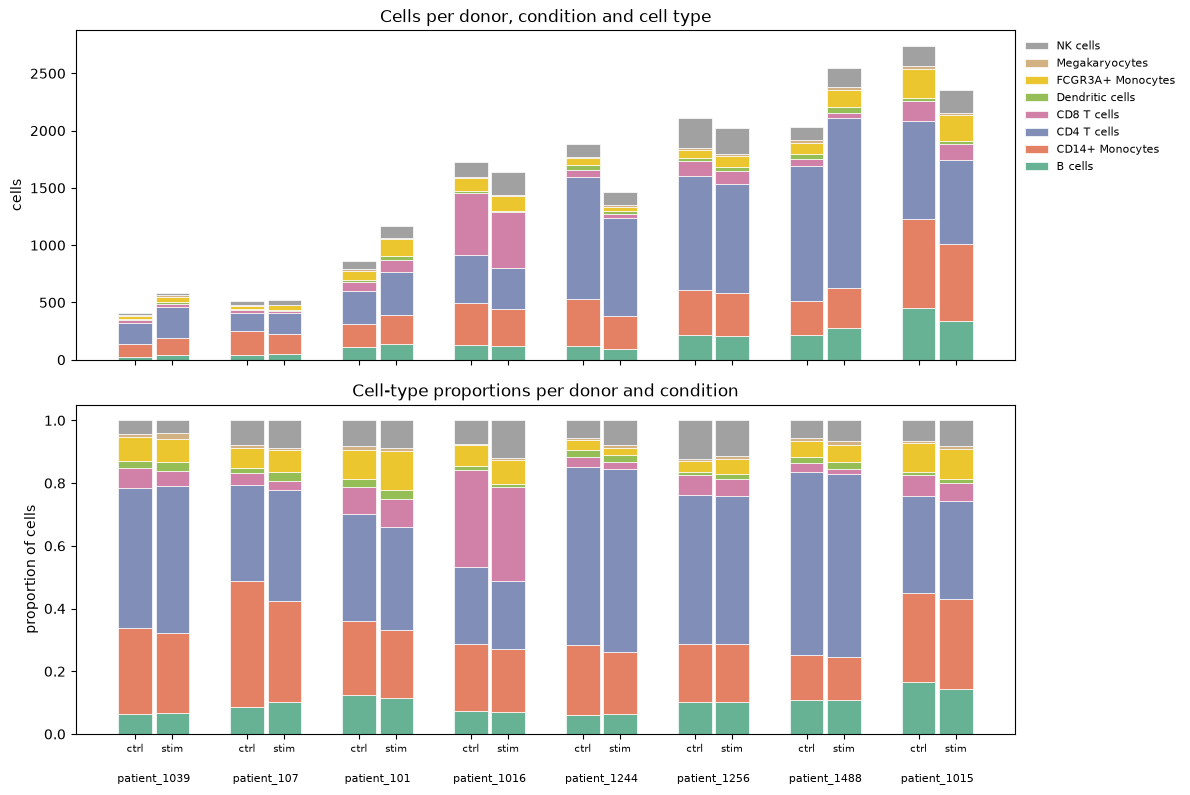

In [4]:
# Typed by hand from audit/data_facts.md, "Cells per donor × condition".
facts = pd.DataFrame({
    "ctrl": [408, 517, 858, 1723, 1879, 2108, 2030, 2738],
    "stim": [584, 525, 1166, 1635, 1464, 2026, 2549, 2352],
}, index=["patient_1039", "patient_107", "patient_101", "patient_1016", "patient_1244", "patient_1256", "patient_1488", "patient_1015"])
expected = facts.stack().tolist()  # donor order, ctrl then stim

cells = ad.read_h5ad(ROOT / "data/processed/m0_cells.h5ad", backed="r")
real_counts = F.composition_counts(cells.obs)
real_fig = F.plot_fig1(real_counts)
bar_totals = bar_values(real_fig.axes[0]).sum(axis=1).astype(int).tolist()

compare(pd.DataFrame({
    "input: bar": [f"{d} {c}" for d, c in facts.stack().index],
    "expected": expected, "code gives": bar_totals,
}), "2 bar totals")
compare(pd.DataFrame({"input": ["sum of all bars", "proportion bars each sum to 1"],
                      "expected": [24562, True],
                      "code gives": [sum(bar_totals),
                                     bool(np.allclose(bar_values(real_fig.axes[1]).sum(axis=1), 1.0))]}),
        "2 grand total")

## 3. UMAP recipe (`compute_umap`) uses exactly C2 and leaves raw counts alone

**Should do:** run, in order, normalize_total → log1p → HVG → scale → PCA → neighbors → UMAP with every C2 and
pinned parameter passed explicitly, no integration (C1), and not change the input's `X`.

Each scanpy step is wrapped so its arguments are **recorded** and the real function then runs unchanged (observe
only). Toy: 300 cells × 2,500 genes of Poisson counts (enough genes for 2,000 HVGs and 50 PCs).

In [5]:
rng = np.random.default_rng(0)
means = rng.gamma(0.5, 2.0, size=2500)
toy = ad.AnnData(X=sp.csr_matrix(rng.poisson(means, size=(300, 2500)).astype(np.float32)),
                 obs=pd.DataFrame(index=[f"c{i}" for i in range(300)]),
                 var=pd.DataFrame(index=[f"g{i}" for i in range(2500)]))
X_before = toy.X.copy()

STEPS = [("pp", "normalize_total"), ("pp", "log1p"), ("pp", "highly_variable_genes"), ("pp", "scale"),
         ("pp", "pca"), ("pp", "neighbors"), ("tl", "umap"), ("tl", "pca"), ("pp", "combat")]
calls = []

def recorder(name, orig):
    def wrapped(*args, **kwargs):
        data = args[0] if args else kwargs.get("adata", kwargs.get("data"))
        calls.append((name, kwargs, getattr(data, "n_vars", None)))
        return orig(*args, **kwargs)
    return wrapped

patches = [mock.patch.object(getattr(sc, mod), fn, recorder(fn, getattr(getattr(sc, mod), fn)))
           for mod, fn in STEPS if hasattr(getattr(sc, mod), fn)]
for p in patches:
    p.start()
try:
    umap = F.compute_umap(toy)
finally:
    for p in patches:
        p.stop()

NOT_PASSED = "<not passed>"
kw = {}
for name, k, _ in calls:
    kw.setdefault(name, k)
nvars = {name: n for name, _, n in calls}
got = lambda step, p: kw.get(step, {}).get(p, NOT_PASSED)

# Expected, from decisions.md C2 + "Pinned defaults (approved)" (Figs row and normalize_total/log1p).
cases = [
    ("normalize_total", "target_sum", 1e4), ("normalize_total", "exclude_highly_expressed", False),
    ("log1p", "base", None),  # natural log, passed explicitly
    ("highly_variable_genes", "n_top_genes", 2000), ("highly_variable_genes", "flavor", "seurat"),
    ("highly_variable_genes", "n_bins", 20), ("highly_variable_genes", "batch_key", None),
    ("scale", "max_value", 10),
    ("pca", "n_comps", 50), ("pca", "svd_solver", "arpack"),
    ("neighbors", "n_neighbors", 15), ("neighbors", "n_pcs", 30), ("neighbors", "metric", "euclidean"),
    ("umap", "min_dist", 0.5), ("umap", "spread", 1.0), ("umap", "init_pos", "spectral"), ("umap", "random_state", 0),
]
compare(pd.DataFrame({
    "input: step": [s for s, _, _ in cases], "parameter": [p for _, p, _ in cases],
    "expected": [e for _, _, e in cases], "code gives": [got(s, p) for s, p, _ in cases],
}), "3 C2 parameters")

compare(pd.DataFrame({
    "input": ["call order", "genes entering PCA (HVGs kept)", "integration call (combat) made",
              "neighbors on an integrated rep", "input X unchanged", "output index = obs_names",
              "output columns", "all coordinates finite"],
    "expected": [["normalize_total", "log1p", "highly_variable_genes", "scale", "pca", "neighbors", "umap"],
                 2000, False, False, True, True, ["umap1", "umap2"], True],
    "code gives": [[n for n, _, _ in calls], nvars.get("pca"), "combat" in kw,
                   got("neighbors", "use_rep") not in (NOT_PASSED, None, "X_pca"),
                   bool((toy.X != X_before).nnz == 0 and toy.X.dtype == X_before.dtype),
                   umap.index.equals(toy.obs_names), list(umap.columns),
                   bool(np.isfinite(umap[["umap1", "umap2"]].to_numpy()).all())],
}), "3 recipe shape")

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


/Users/prakritipaul/anaconda3/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


/Users/prakritipaul/Git/IFNbeta-immune-celltype-txn-effects/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,input: step,parameter,expected,code gives,match
0,normalize_total,target_sum,10000.0,10000.0,True
1,normalize_total,exclude_highly_expressed,False,False,True
2,log1p,base,None,None,True
3,highly_variable_genes,n_top_genes,2000,2000,True
4,highly_variable_genes,flavor,seurat,seurat,True
5,highly_variable_genes,n_bins,20,20,True
6,highly_variable_genes,batch_key,None,None,True
7,scale,max_value,10,10,True
8,pca,n_comps,50,50,True
9,pca,svd_solver,arpack,arpack,True


,input,expected,code gives,match
0,call order,"[normalize_total, log1p, highly_variable_genes...","[normalize_total, log1p, highly_variable_genes...",True
1,genes entering PCA (HVGs kept),2000,2000,True
2,integration call (combat) made,False,False,True
3,neighbors on an integrated rep,False,False,True
4,input X unchanged,True,True,True
5,output index = obs_names,True,True,True
6,output columns,"[umap1, umap2]","[umap1, umap2]",True
7,all coordinates finite,True,True,True


## 4. I3 on the saved embedding (`data/processed/f2_umap.csv`)

**Should do:** one row per cell, 24,562 unique barcodes, exactly the cells of `m0_cells.h5ad`, with each cell's
condition matching, and every coordinate finite, so both Fig 2 panels plot the same cells at the same places.

In [6]:
emb = pd.read_csv(ROOT / "data/processed/f2_umap.csv")
compare(pd.DataFrame({
    "input": ["rows", "unique barcodes", "same barcode set as m0_cells.h5ad", "condition matches m0_cells.h5ad",
              "all umap1/umap2 finite", "columns"],
    "expected": [24562, 24562, True, True, True, ["barcode", "condition", "umap1", "umap2"]],
    "code gives": [len(emb), emb["barcode"].nunique(), set(emb["barcode"]) == set(cells.obs_names),
                   bool((emb.set_index("barcode")["condition"].reindex(cells.obs_names).astype(str)
                         == cells.obs["condition"].astype(str)).all()),
                   bool(np.isfinite(emb[["umap1", "umap2"]].to_numpy()).all()), list(emb.columns)],
}), "4 I3")
display(emb.head(3), emb.tail(3))

,input,expected,code gives,match
0,rows,24562,24562,True
1,unique barcodes,24562,24562,True
2,same barcode set as m0_cells.h5ad,True,True,True
3,condition matches m0_cells.h5ad,True,True,True
4,all umap1/umap2 finite,True,True,True
5,columns,"[barcode, condition, umap1, umap2]","[barcode, condition, umap1, umap2]",True


,barcode,condition,umap1,umap2
0,AAACATACATTTCC-1,ctrl,-1.114449,10.241630
1,AAACATACCAGAAA-1,ctrl,-1.115222,14.148938
2,AAACATACCATGCA-1,ctrl,12.869485,2.294503


,barcode,condition,umap1,umap2
24559,TTTGCATGCTAAGC-2,stim,9.356835,6.850413
24560,TTTGCATGGGACGA-2,stim,9.117835,7.425764
24561,TTTGCATGTCTTAC-2,stim,11.114378,9.225468


## Result

In [7]:
print("mismatches:", FAILURES or "none")
assert not FAILURES, f"POSSIBLE BUGS: {FAILURES}"

mismatches: none
